# Analisi linea umana (MCF10 EV, MCF10 RAB5) — unità = cellula

Nel monostrato ogni curva è acquisita su una **cellula diversa** (6–7 curve per area, una per cellula):
**ogni curva è una cellula**. La sottocartella dell'area resta solo come etichetta e non viene usata per fare medie.
- **Forza-indentazione**: ogni curva è fittata con Ting ed è un'unità a sé.
- **Stress-relaxation**: ogni curva è normalizzata e fittata da sola (SLS, PLR, bi-exp, poroelastico).

Alla fine: tabella per cellula, curva SR media di ciascuna linea, test di Mann–Whitney tra le due linee (una osservazione per cellula).

**Da modificare:** solo la cella 2 (cartelle delle due linee).

**Nota:** gli output già salvati precedono la rampa di chiusura al contatto e i nuovi criteri di esclusione. Rieseguire la cella di analisi completa per aggiornare i risultati in `aggregated/per_cellula_umane_chiusura_contatto`; l'esclusione del 10/06/26 per EV e RAB5 resta attiva.

In [25]:
# 1. Import
import sys
sys.path.insert(0, r'/Users/furbetta/Desktop/PyFMlab_DyNaMo/PyFMGUI_DyNaMo')
sys.path.insert(0, r'/Users/furbetta/Desktop/PyFMlab_DyNaMo/PyFMGUI_DyNaMo/general/src')

import importlib
import warnings
import matplotlib.pyplot as plt
import analisi_per_cellula as apc
importlib.reload(apc)

warnings.filterwarnings("ignore")
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

sr_utils: uso il file /Users/furbetta/Desktop/PyFMlab_DyNaMo/PyFMGUI_DyNaMo/sr_utils.py


In [26]:
# 2. Configurazione
SISTEMA = "umane"

# Per ogni linea: le cartelle delle giornate. Dentro ciascuna: <area>/FD e <area>/SR
LINEE = {
    "EV": [
        r"/Users/furbetta/Desktop/PyFMlab_DyNaMo/PyFMGUI_DyNaMo/MCF10_EV_090626",
        r"/Users/furbetta/Desktop/PyFMlab_DyNaMo/PyFMGUI_DyNaMo/MCF10_EV_100626",
        r"/Users/furbetta/Desktop/PyFMlab_DyNaMo/PyFMGUI_DyNaMo/MCF10_EV_130526",
        r"/Users/furbetta/Desktop/PyFMlab_DyNaMo/PyFMGUI_DyNaMo/MCF10_EV_140526",
        r"/Users/furbetta/Desktop/PyFMlab_DyNaMo/PyFMGUI_DyNaMo/MCF10_EV_250626",
        r"/Users/furbetta/Desktop/PyFMlab_DyNaMo/PyFMGUI_DyNaMo/MCF10_EV_260626",
        # aggiungi qui le altre giornate EV
    ],
    "RAB5": [
        r"/Users/furbetta/Desktop/PyFMlab_DyNaMo/PyFMGUI_DyNaMo/MCF10_RAB5_090626",
        r"/Users/furbetta/Desktop/PyFMlab_DyNaMo/PyFMGUI_DyNaMo/MCF10_RAB5_100626",
        r"/Users/furbetta/Desktop/PyFMlab_DyNaMo/PyFMGUI_DyNaMo/MCF10_RAB5_150626",
        r"/Users/furbetta/Desktop/PyFMlab_DyNaMo/PyFMGUI_DyNaMo/MCF10_RAB5_160626",
        r"/Users/furbetta/Desktop/PyFMlab_DyNaMo/PyFMGUI_DyNaMo/MCF10_RAB5_250626",
        r"/Users/furbetta/Desktop/PyFMlab_DyNaMo/PyFMGUI_DyNaMo/MCF10_RAB5_260626",
        # aggiungi qui le altre giornate RAB5
    ],
}

OUTPUT_DIR = r"/Users/furbetta/Desktop/PyFMlab_DyNaMo/PyFMGUI_DyNaMo/aggregated/per_cellula_umane_chiusura_contatto"
ESEGUI_FD = True
ESEGUI_SR = True
ESCLUDI_GIORNATE = ["100626"]
CRITERI = dict(apc.CRITERI_UMANE)
CRITERI["sr_F_relax_fisico"] = False
OPZIONI_TING = {"drag_mode": "minimo_cartella", "param_overrides": {"apply_ramp_correction": True}}
OPZIONI_SR = {"drag_correction": True}
ALTEZZE_UM = {"EV": 7.0, "RAB5": 7.0}

In [27]:
# 3. Controllo: quali cellule vengono trovate (nessun fit)
cells = apc.find_cells(LINEE, SISTEMA)
apc.print_cells_overview(cells)
display(cells[["linea", "giornata", "cartella", "tipo", "id_cellula", "n_curve"]].head(20))

Cellule trovate:


,linea,tipo,giornate,cellule,curve
0,EV,FD,6,233,233
1,EV,SR,6,225,225
2,RAB5,FD,6,263,263
3,RAB5,SR,6,267,270


,linea,giornata,cartella,tipo,id_cellula,n_curve
0,EV,MCF10_EV_090626,cell01,FD,MCF10_EV_090626/cell01/Area1_FD-0000,1
1,EV,MCF10_EV_090626,cell01,FD,MCF10_EV_090626/cell01/Area1_FD-0001,1
2,EV,MCF10_EV_090626,cell01,FD,MCF10_EV_090626/cell01/Area1_FD-0002,1
3,EV,MCF10_EV_090626,cell01,FD,MCF10_EV_090626/cell01/Area1_FD-0003,1
4,EV,MCF10_EV_090626,cell01,FD,MCF10_EV_090626/cell01/Area1_FD-0004,1
5,EV,MCF10_EV_090626,cell01,FD,MCF10_EV_090626/cell01/Area1_FD-0005,1
6,EV,MCF10_EV_090626,cell01,SR,MCF10_EV_090626/cell01/Area1_SR-0000,1
7,EV,MCF10_EV_090626,cell01,SR,MCF10_EV_090626/cell01/Area1_SR-0001,1
8,EV,MCF10_EV_090626,cell01,SR,MCF10_EV_090626/cell01/Area1_SR-0002,1
9,EV,MCF10_EV_090626,cell01,SR,MCF10_EV_090626/cell01/Area1_SR-0003,1


Giornate escluse dall'analisi: ['MCF10_EV_100626', 'MCF10_RAB5_100626']

Resistenza viscosa: distanza minima tra i rami per area, mediana per giornata (lettura dei file FD)...
  EV MCF10_EV_090626: 0.096 nN
  EV MCF10_EV_130526: 0.056 nN
  EV MCF10_EV_140526: 0.083 nN
  EV MCF10_EV_250626: 0.056 nN
  EV MCF10_EV_260626: 0.078 nN
  RAB5 MCF10_RAB5_090626: 0.135 nN
  RAB5 MCF10_RAB5_150626: 0.086 nN
  RAB5 MCF10_RAB5_160626: 0.075 nN
  RAB5 MCF10_RAB5_250626: 0.053 nN
  RAB5 MCF10_RAB5_260626: 0.068 nN
Cellule trovate:


,linea,tipo,giornate,cellule,curve
0,EV,FD,5,169,169
1,EV,SR,5,162,162
2,RAB5,FD,5,190,190
3,RAB5,SR,5,192,195



=== Curve forza-indentazione ===
ting_utils: uso il file /Users/furbetta/Desktop/PyFMlab_DyNaMo/PyFMGUI_DyNaMo/ting_utils.py
[FD 1/359] MCF10_EV_090626/cell01/Area1_FD-0000 - Area1_FD-0000.jpk-force


[TingFit] Warning: Hertz delta0=712019.1nm diverged (z_range=8476.7nm). Using RoV PoC only (delta0=0).


[FD 2/359] MCF10_EV_090626/cell01/Area1_FD-0001 - Area1_FD-0001.jpk-force
[FD 3/359] MCF10_EV_090626/cell01/Area1_FD-0002 - Area1_FD-0002.jpk-force
[FD 4/359] MCF10_EV_090626/cell01/Area1_FD-0003 - Area1_FD-0003.jpk-force
[FD 5/359] MCF10_EV_090626/cell01/Area1_FD-0004 - Area1_FD-0004.jpk-force
[FD 6/359] MCF10_EV_090626/cell01/Area1_FD-0005 - Area1_FD-0005.jpk-force
[FD 7/359] MCF10_EV_090626/cell02/Area2_FD-0000 - Area2_FD-0000.jpk-force


...

[FD 354/359] MCF10_RAB5_260626/cell03/Area3-0005 - Area3-0005.jpk-force


[TingFit] Warning: Hertz delta0=713490.8nm diverged (z_range=9145.3nm). Using RoV PoC only (delta0=0).


[FD 355/359] MCF10_RAB5_260626/cell03/Area3-0007 - Area3-0007.jpk-force


[TingFit] Warning: Hertz delta0=713834.3nm diverged (z_range=9593.1nm). Using RoV PoC only (delta0=0).
[TingFit] Warning: Hertz delta0=715128.8nm diverged (z_range=8437.2nm). Using RoV PoC only (delta0=0).


[FD 356/359] MCF10_RAB5_260626/cell03/Area3-0009 - Area3-0009.jpk-force
[FD 357/359] MCF10_RAB5_260626/cell04/Area4-0001 - Area4-0001.jpk-force
[FD 358/359] MCF10_RAB5_260626/cell04/Area4-0003 - Area4-0003.jpk-force
[FD 359/359] MCF10_RAB5_260626/cell04/Area4-0005 - Area4-0005.jpk-force
FD: 355 riuscite su 359
FD: errori piu' frequenti (numero di casi):
  [3] errore: TypeError: 'NoneType' object is not subscriptable
  [1] errore: RuntimeError: Contact-closure ramp correction failed: index 0 is out of bounds for axis 0 with size 0


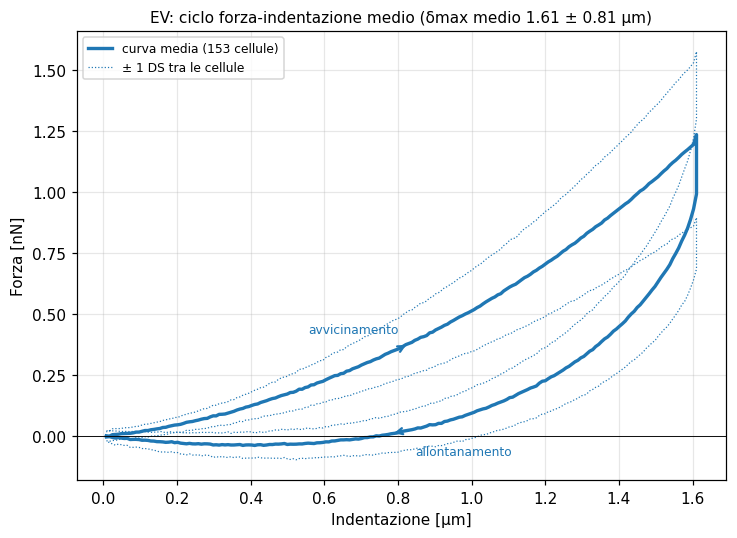

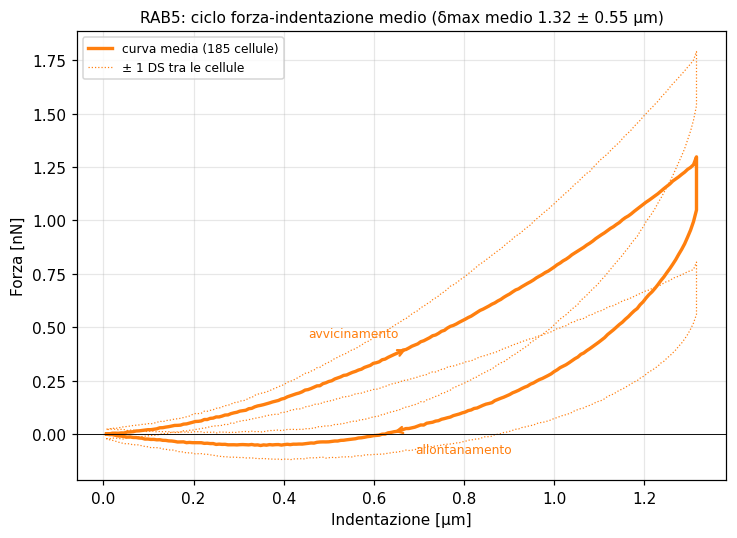

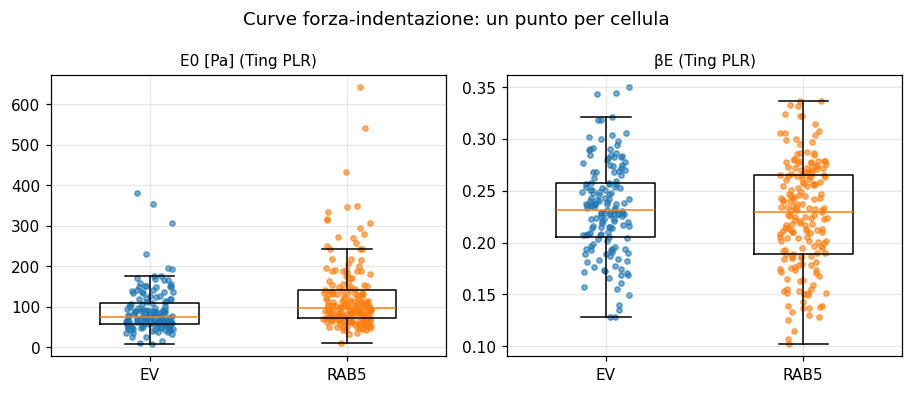


=== Curve di stress-relaxation ===
[SR 1/357] MCF10_EV_090626/cell01/Area1_SR-0000 (1 curve)


,confronto,modello,parametri,RMSE_finestra,R2_finestra,AICc_finestra,dAICc_finestra
0,finestra_iniziale,Poroelastico,"F∞=0.2996, τp=0.0719 s",0.02000,0.98559,-6130.37580,464.20848
1,finestra_iniziale,SLS,"F∞=0.4133, τ=0.0349 s",0.07110,0.81787,-4141.33234,2453.25194
2,finestra_iniziale,PLR (1+t/t0)^-b,"t0=0.00444 s, β=0.2130",0.02433,0.97866,-5822.44520,772.13908
3,finestra_iniziale,Bi-exp GM,"F∞=0.3142, w=0.4011, τ1=0.0054 s, τ2=0.1709 s",0.01483,0.99207,-6594.58428,0.00000
4,intera_curva_da_0,SLS,"F∞=0.2300, τ=0.0834 s",0.11616,0.51380,NaN,NaN
5,intera_curva_da_0,PLR (1+t/t0)^-b,"t0=0.01057 s, β=0.3016",0.04205,0.93630,NaN,NaN
6,intera_curva_da_0,Bi-exp GM,"F∞=0.0921, w=0.4659, τ1=0.0152 s, τ2=0.9325 s",0.03745,0.94946,NaN,NaN


,candidate_t_s,late_model,late_r2,score
1,0.27375,bi,0.989081,0.02299
27,0.86750,plr,0.936020,0.02079


,dominio,modello,parametri,R2
0,early-phase (0-0.868s),Poroelastico,"F∞=0.2970, τp=0.0740 s",0.9914
1,post-transizione (t≥0.868s),Bi-exp GM,"F∞=0.0000, w=0.6850, τ1=0.3175 s, τ2=3.9386 s",0.9824
2,post-transizione (t≥0.868s),PLR puro,"t0=0.1644 s, β=0.6934",0.9493
3,post-transizione (t≥0.868s),SLS,"F∞=0.0912, τ=0.7190 s",0.7453


[SR 2/357] MCF10_EV_090626/cell01/Area1_SR-0001 (1 curve)


...

,candidate_t_s,late_model,late_r2,score
0,0.250,bi,0.996030,0.010639
13,0.535,plr,0.996498,0.029773


,dominio,modello,parametri,R2
0,early-phase (0-0.250s),Poroelastico,"F∞=0.4706, τp=0.0436 s",0.9960
1,post-transizione (t≥0.250s),Bi-exp GM,"F∞=0.2220, w=0.6793, τ1=0.1249 s, τ2=2.4438 s",0.9960
2,post-transizione (t≥0.250s),PLR puro,"t0=0.0131 s, β=0.2246",0.9959
3,post-transizione (t≥0.250s),SLS,"F∞=0.3002, τ=0.2862 s",0.6867


,confronto,modello,parametri,RMSE_finestra,R2_finestra,AICc_finestra,dAICc_finestra
0,finestra_iniziale,Poroelastico,"F∞=0.4782, τp=0.0360 s",0.00817,0.99428,-5658.85926,558.05096
1,finestra_iniziale,SLS,"F∞=0.5761, τ=0.0178 s",0.04079,0.85753,-3764.70864,2452.20158
2,finestra_iniziale,PLR (1+t/t0)^-b,"t0=0.001887 s, β=0.1355",0.00876,0.99344,-5577.36589,639.54433
3,finestra_iniziale,Bi-exp GM,"F∞=0.5013, w=0.4137, τ1=0.0035 s, τ2=0.0744 s",0.00507,0.99780,-6216.91022,0.00000
4,intera_curva_da_0,SLS,"F∞=0.3632, τ=0.0629 s",0.09748,0.18637,NaN,NaN
5,intera_curva_da_0,PLR (1+t/t0)^-b,"t0=0.004443 s, β=0.1829",0.02316,0.95407,NaN,NaN
6,intera_curva_da_0,Bi-exp GM,"F∞=0.2603, w=0.4897, τ1=0.0126 s, τ2=0.7355 s",0.02842,0.93087,NaN,NaN


,candidate_t_s,late_model,late_r2,score
0,0.2500,bi,0.996236,0.012736
6,0.3925,plr,0.993740,0.024919


,dominio,modello,parametri,R2
0,early-phase (0-0.250s),Poroelastico,"F∞=0.4712, τp=0.0387 s",0.9955
1,post-transizione (t≥0.250s),Bi-exp GM,"F∞=0.2071, w=0.6773, τ1=0.1246 s, τ2=2.5808 s",0.9962
2,post-transizione (t≥0.250s),PLR puro,"t0=0.0141 s, β=0.2335",0.9934
3,post-transizione (t≥0.250s),SLS,"F∞=0.2912, τ=0.2860 s",0.6757


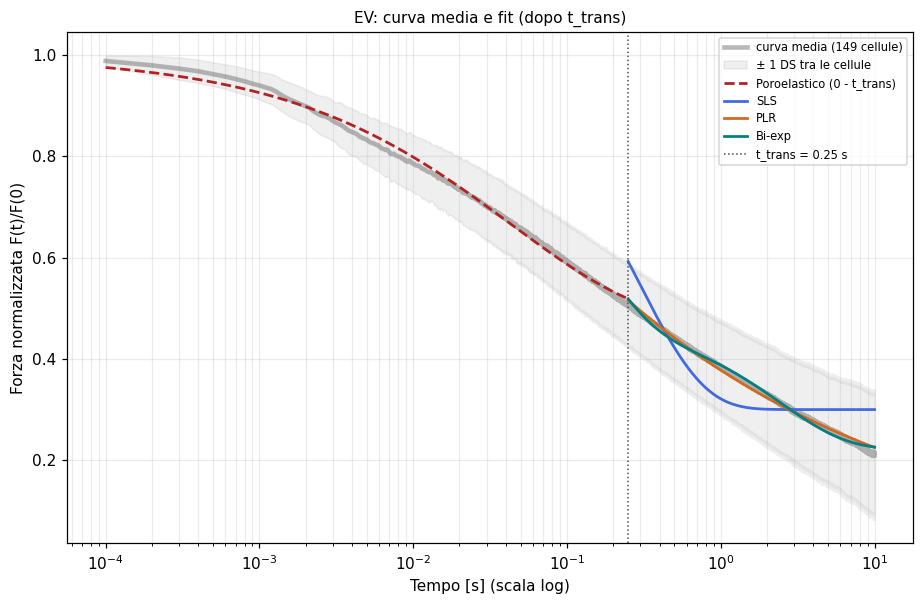

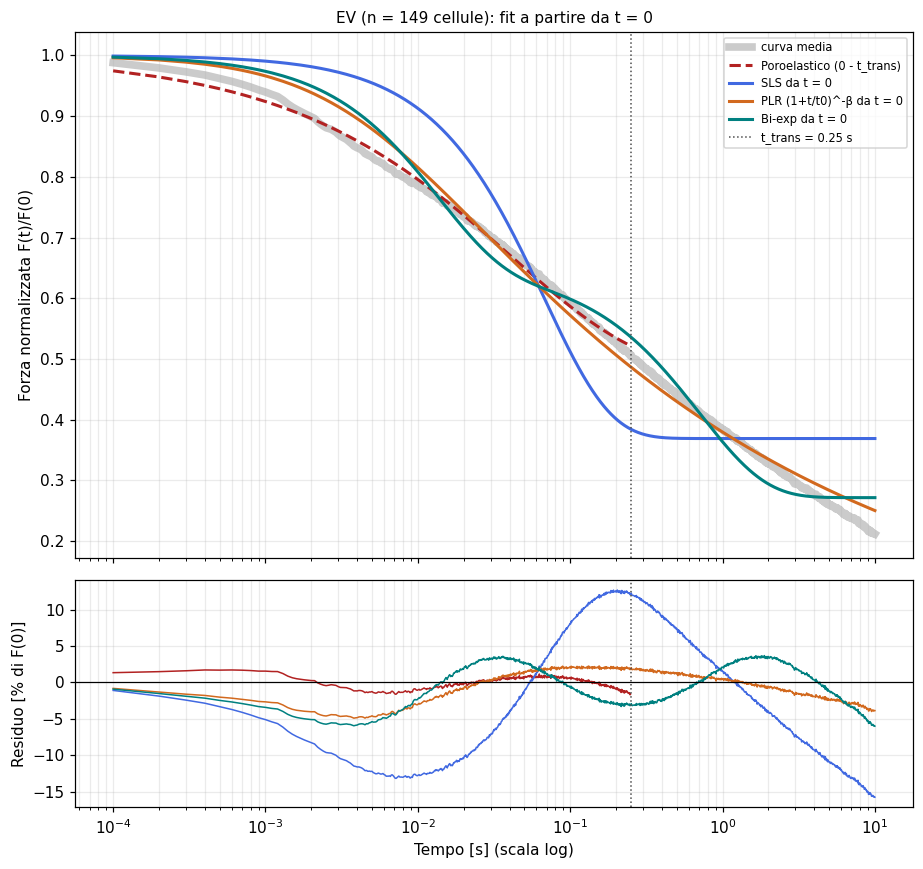

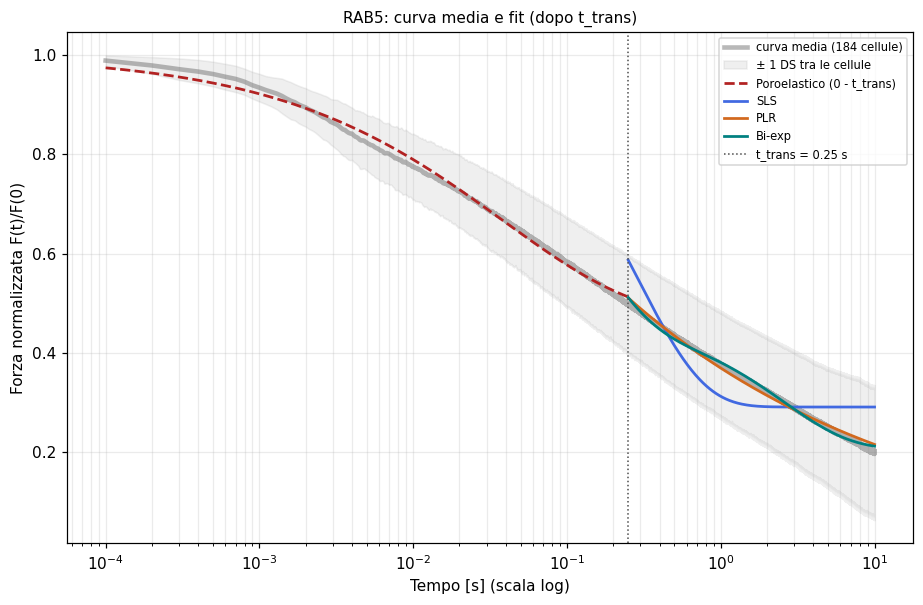

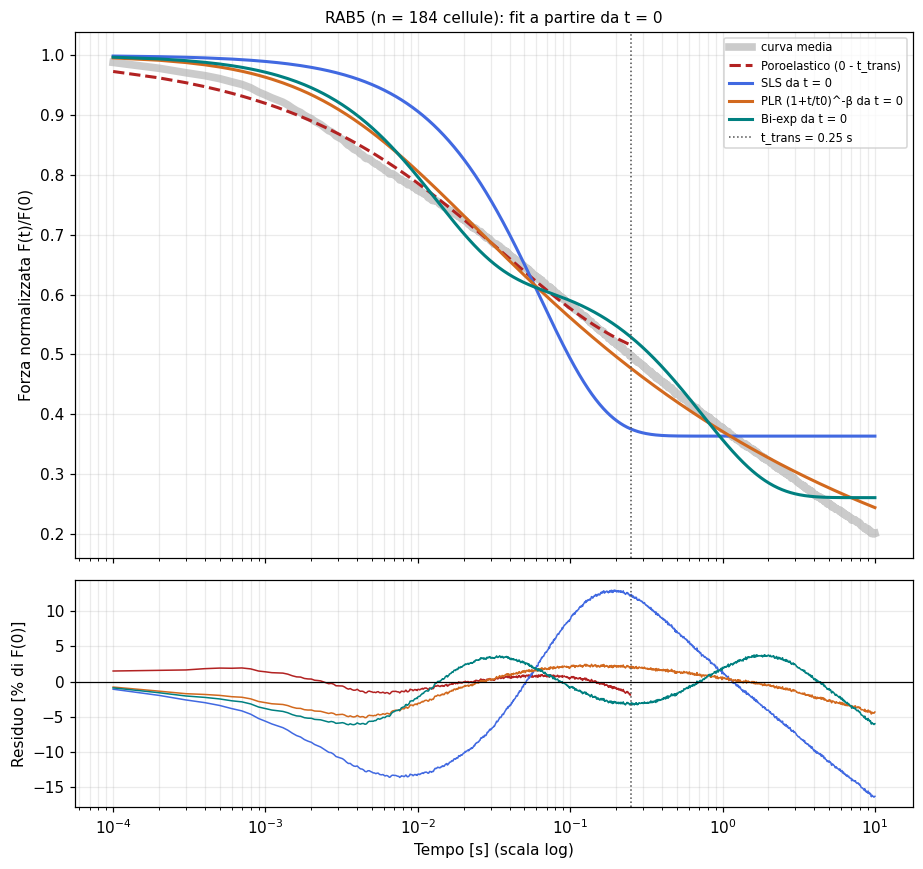

SR - fit sulla curva media di ciascuna linea:


,linea,n_cellule,F_0.1s,F_1s,F_relax,rilassamento_pct,SLS_F_inf,SLS_tau_s,PLR_beta,PLR_t0_s,BI_F_inf,BI_w,BI_tau1_s,BI_tau2_s,PORO_tau_p_s,t_trans_s
0,EV,149,0.5925,0.3842,0.1737,82.6284,0.3002,0.2862,0.2246,0.0131,0.2220,0.6793,0.1249,2.4438,0.0436,0.25
1,RAB5,184,0.5827,0.3761,0.1698,83.0189,0.2912,0.2860,0.2335,0.0141,0.2071,0.6773,0.1246,2.5808,0.0387,0.25



Criteri di esclusione: {'fd_r2_min': 0.7, 'fd_betaE_at_bound': True, 'fd_max_rapporto_hertz_E0': 10.0, 'sr_F_relax_fisico': False, 'sr_r2_min': 0.7, 'sr_beta_at_bound': True}
Tenute dopo i criteri (dettaglio in esclusi_umane.csv):


,,EV,RAB5
0,FD: curve,153 su 165,185 su 190
1,FD: cellule,153 su 165,185 su 190
2,SR: cellule,149 su 162,184 su 195



Riassunto forza-indentazione (media ± DS tra le cellule; p del test di Mann-Whitney sulle cellule):


,grandezza,EV,RAB5,p (Mann-Whitney)
0,Ting PLR: E0 [Pa],89.5 ± 54.8 (n=153),122 ± 85.9 (n=185),4.14e-06
1,Ting PLR: βE,0.233 ± 0.0439 (n=153),0.226 ± 0.0515 (n=185),0.34
2,Hertz: E [Pa],181 ± 95.7 (n=153),230 ± 108 (n=185),3.08e-07
3,Ting PLR: E0 corretto spessore [Pa],58.4 ± 40 (n=153),81.8 ± 61.2 (n=185),1.75e-06
4,Hertz: E corretto spessore [Pa],118 ± 70.9 (n=153),154 ± 78.7 (n=185),1.18e-07
5,Ting PLR: E0 corretto (coeff. Garcia) [Pa],56.3 ± 39.2 (n=153),79.3 ± 59.8 (n=185),1.45e-06
6,fattore di correzione (Dimitriadis),1.61 ± 0.209 (n=153),1.53 ± 0.144 (n=185),3.36e-05
7,indentazione massima [µm],1.61 ± 0.812 (n=153),1.32 ± 0.55 (n=185),3.29e-05



Riassunto stress-relaxation (media ± DS tra le cellule; p del test di Mann-Whitney sulle cellule):


,grandezza,EV,RAB5,p (Mann-Whitney)
0,"forza a 0,1 s (F/F0)",0.592 ± 0.0741 (n=149),0.583 ± 0.0891 (n=184),0.228
1,forza a 1 s (F/F0),0.384 ± 0.0898 (n=149),0.376 ± 0.105 (n=184),0.31
2,forza residua F_relax (F/F0),0.174 ± 0.149 (n=149),0.17 ± 0.144 (n=184),0.606
3,rilassamento ΔF [%],82.6 ± 14.9 (n=149),83 ± 14.4 (n=184),0.606
4,SLS: F∞,0.291 ± 0.101 (n=149),0.281 ± 0.109 (n=184),0.319
5,SLS: τ [s],0.359 ± 0.142 (n=149),0.369 ± 0.161 (n=184),0.703
6,PLR: β,0.262 ± 0.202 (n=149),0.268 ± 0.167 (n=184),0.161
7,Bi-exp: F∞,0.194 ± 0.122 (n=149),0.183 ± 0.121 (n=184),0.233
8,Bi-exp: w,0.654 ± 0.105 (n=149),0.651 ± 0.0958 (n=184),0.617
9,Bi-exp: τ1 [s],0.137 ± 0.0678 (n=149),0.134 ± 0.0682 (n=184),0.756


Figura per la tesi salvata: fig_tesi_box_umane.pdf
Figura per la tesi salvata: fig_tesi_FD_media_umane.pdf
Figura per la tesi salvata: fig_tesi_SR_media_umane.pdf
Figura per la tesi salvata: fig_tesi_SR_media_umane_lineare.pdf

Tabelle e report salvati in: /Users/furbetta/Desktop/PyFMlab_DyNaMo/PyFMGUI_DyNaMo/aggregated/per_cellula_umane_chiusura_contatto


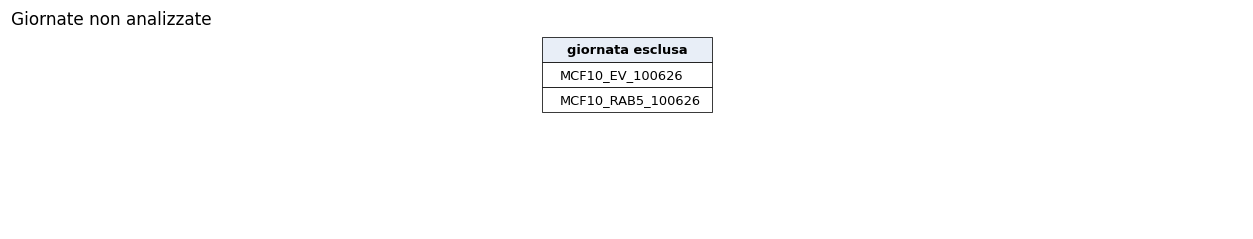

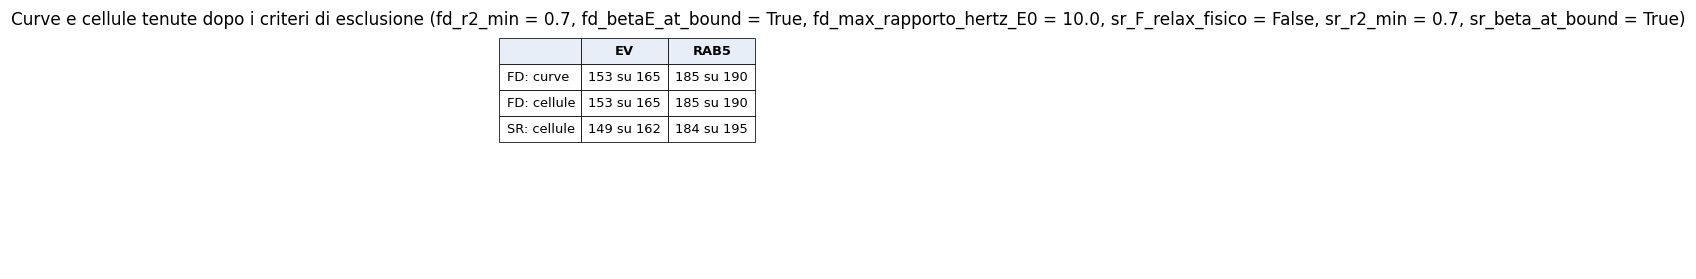

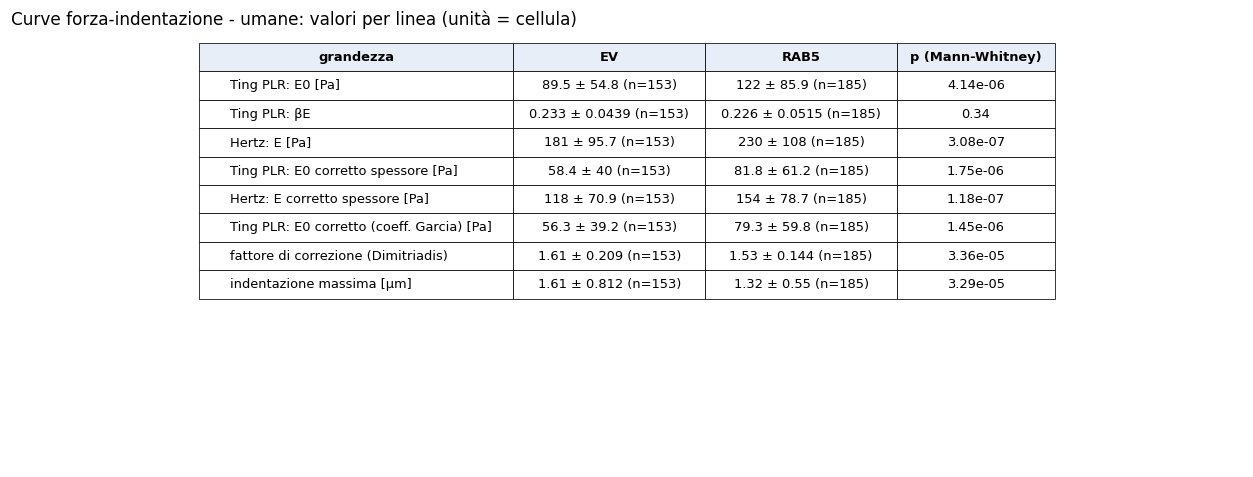

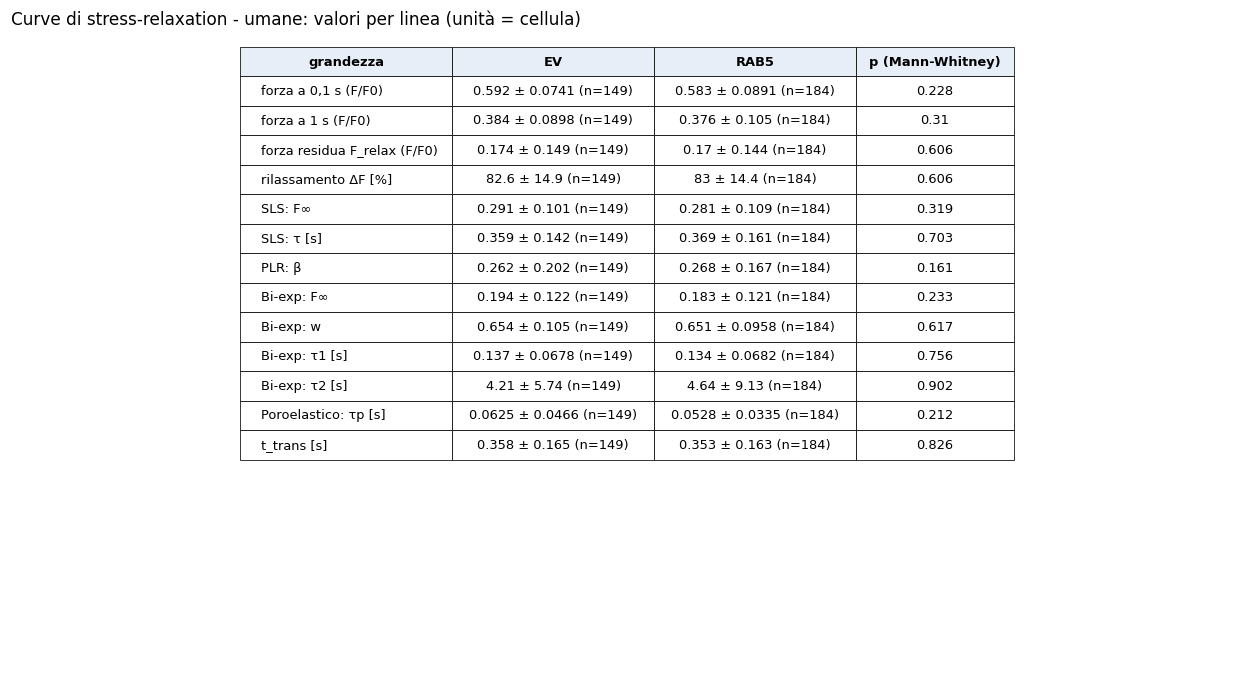

In [28]:
# 4. Analisi completa: FD (Ting) e SR, tabelle per cellula, medie per linea, test
risultati = apc.run_full_analysis(
    LINEE,
    SISTEMA,
    OUTPUT_DIR,
    run_fd=ESEGUI_FD,
    run_sr=ESEGUI_SR,
    criteri=CRITERI,
    escludi_giornate=ESCLUDI_GIORNATE,
    ting_options=OPZIONI_TING,
    sr_options=OPZIONI_SR,
    altezze_um=ALTEZZE_UM,
)